In [1]:
import pandas as pd 

df=pd.read_csv("../data/Titanic-Dataset.csv")

df.head()
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Survived', 'PassengerId', 'Name', 'Cabin', 'Ticket'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [3]:
age_median = X_train['Age'].median()
embarked_mode = X_train['Embarked'].mode()[0]

X_train['Age'] = X_train['Age'].fillna(age_median)
X_train['Embarked'] = X_train['Embarked'].fillna(embarked_mode)

X_test['Age'] = X_test['Age'].fillna(age_median)
X_test['Embarked'] = X_test['Embarked'].fillna(embarked_mode)
X_train.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [4]:
X_train = pd.get_dummies(
    X_train,
    columns=['Sex', 'Embarked'],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=['Sex', 'Embarked'],
    dtype=int
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_train.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,3,28.5,0,0,56.4958,0,1,0,0,1
481,2,28.5,0,0,0.0000,0,1,0,0,1
527,1,28.5,0,0,221.7792,0,1,0,0,1
855,3,18.0,0,1,9.3500,1,0,0,0,1
801,2,31.0,1,1,26.2500,1,0,0,0,1


In [5]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

pred = model.predict(X_test)


In [6]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, pred)

0.8044692737430168

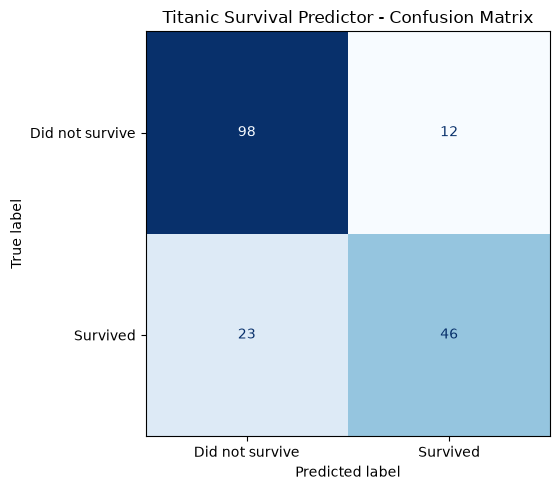

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Did not survive', 'Survived']
)

fig, ax = plt.subplots(figsize=(7, 5))

display.plot(
    ax=ax,
    cmap='Blues',
    values_format='d',
    colorbar=False
)

ax.set_title('Titanic Survival Predictor - Confusion Matrix')

plt.tight_layout()
plt.show()